# Customer Churn Prediction Using Machine Learning

**Project Type:** Supervised Machine Learning – Binary Classification

**Dataset:** IBM Telco Customer Churn Dataset (Kaggle)

**Objective:** To predict whether a customer is likely to leave a telecommunications company or continue using its services.

## 1.1 Problem Statement

Predict whether a telecommunications customer will leave the company (customer churn) for existing telecom customers using demographic information, account details, subscription services, and billing characteristics, so that customer retention teams can identify at-risk customers and decide which customers need targeted retention strategies.

## 1.2 Project Objectives

- Explore customer data through Exploratory Data Analysis (EDA).
- Identify factors associated with customer churn.
- Prepare the dataset for machine learning.
- Train and compare multiple classification models.
- Evaluate model performance using suitable metrics.
- Analyze incorrect predictions and their possible causes.

## 1.3 Machine Learning Approach

- **Learning Type:** Supervised Learning
- **Problem Type:** Binary Classification
- **Target Variable:** `Churn`
- **Classes:** Yes (Churn) and No (No Churn)

## 2. Importing Required Libraries

- The required libraries are imported for data manipulation and numerical operations.
- Visualization libraries are included to create charts and graphs.
- Scikit-learn tools are imported for preprocessing, model training, and evaluation.

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Dataset splitting and cross-validation
from sklearn.model_selection import train_test_split, cross_val_score

# Baseline model
from sklearn.dummy import DummyClassifier

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score
)

# Display settings
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

# Reproducibility
RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


## 3. Loading the Dataset

- The IBM Telco Customer Churn dataset is obtained from Kaggle.
- The CSV file is loaded into a Pandas DataFrame.
- The dataset contains customer demographics, services, and billing information.

In [ ]:
# Load the Kaggle dataset
df = pd.read_csv("Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 4. Initial Dataset Inspection

- The total number of rows and columns is examined.
- Column names and data types are inspected.
- The first five records are displayed to understand the dataset structure.

In [ ]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

Dataset Shape: (7043, 21)


In [ ]:
# First five records
display(df.head())


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Column names
print("\nDataset Columns:")
print(df.columns.tolist())



Dataset Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [ ]:
# Dataset information
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

## 5. Checking Missing Values and Duplicates

- Missing values are identified in each column.
- The percentage of missing data is calculated.
- Duplicate records are checked to assess data quality.

In [ ]:
# Missing values summary
print("Missing Values Summary:")
print(df.isnull().sum())


Missing Values Summary:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [ ]:
# Duplicate records
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


## 6. Understanding the Target Variable

- The distribution of the `Churn` target variable is examined.
- The number and percentage of customers who left or stayed are calculated.
- A count plot is created to visualize the distribution of churn categories.

In [ ]:
# Count churn categories
print("Churn Counts:")
print(df['Churn'].value_counts())

Churn Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [ ]:
# Calculate percentages
print("\nChurn Percentages:")
churn_percentages = (df['Churn'].value_counts(normalize=True)*100).round(2)
print(churn_percentages)


Churn Percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


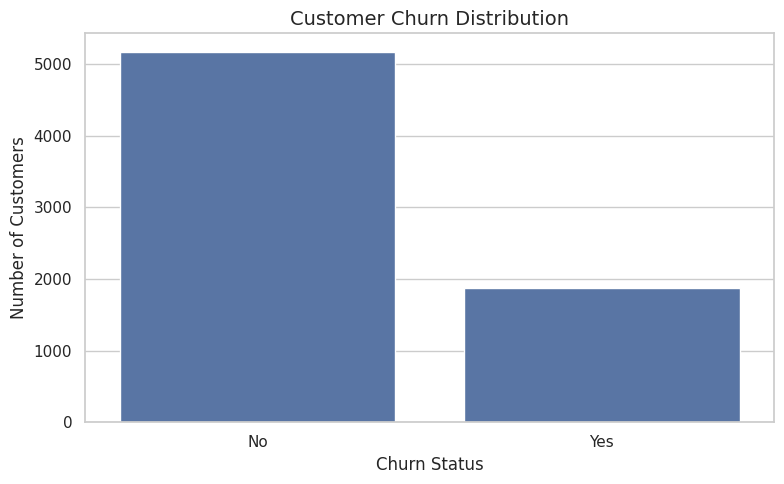

In [ ]:
# Visualize churn distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution', fontsize=14)
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

## 7. Data Type Correction

The `TotalCharges` column is stored as an object instead of a numeric data type.

- 11 blank values were identified in `TotalCharges`.
- No other blank or missing values were found.
- The blank values will be converted into missing values before numerical preprocessing.

In [ ]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("Updated Data Type:", df['TotalCharges'].dtype)
print("Missing TotalCharges Values:", df['TotalCharges'].isnull().sum())

Updated Data Type: float64
Missing TotalCharges Values: 11


In [ ]:
print("Missing Values After Conversion:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values After Conversion:
TotalCharges    11
dtype: int64

Total Missing Values: 11


## 8. Exploratory Data Analysis (EDA)
Exploratory Data Analysis is performed to understand customer characteristics and identify patterns associated with customer churn.



### 8.1 Customer Tenure Distribution

The distribution of customer tenure is examined to understand how long customers have stayed with the telecommunications company.

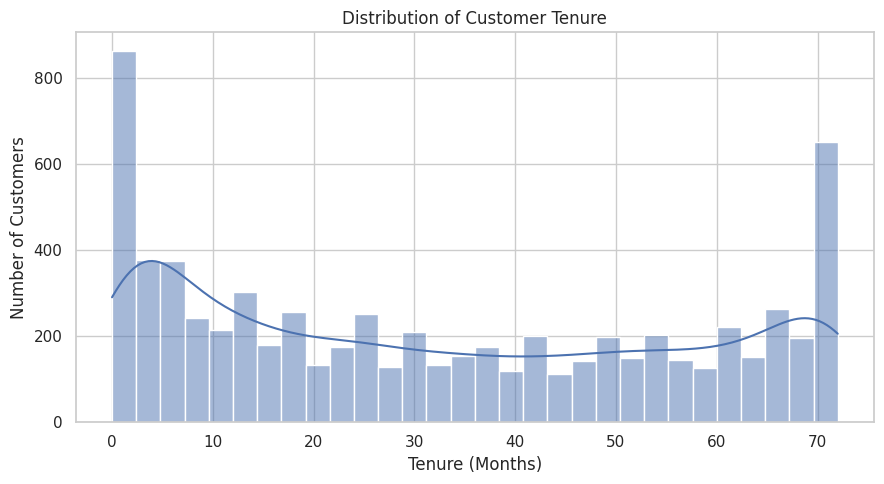

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='tenure', bins=30, kde=True)

plt.title('Distribution of Customer Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

### 8.2 Contract Type vs Customer Churn

The relationship between contract types and customer churn is examined to identify whether customers with different contract durations have different churn patterns.

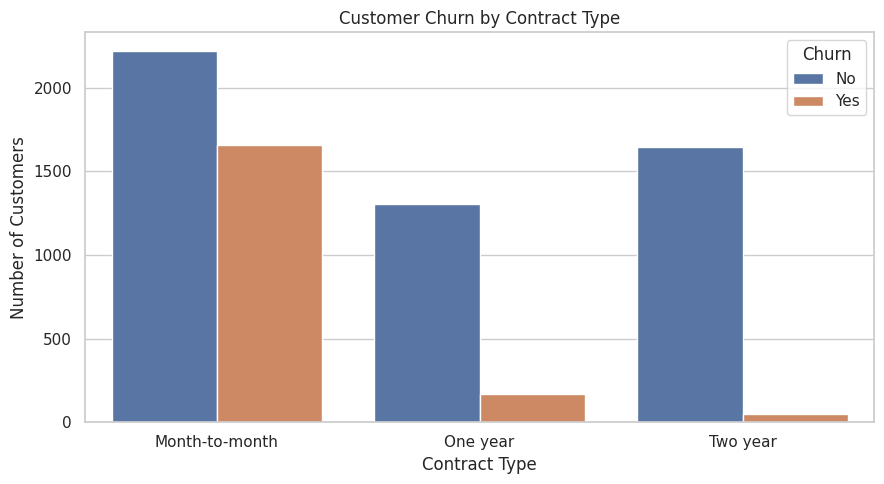

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x='Contract', hue='Churn')

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.tight_layout()
plt.show()

### 8.3 Monthly Charges vs Customer Churn

The distribution of monthly charges is compared between customers who churn and those who continue using the company's services.

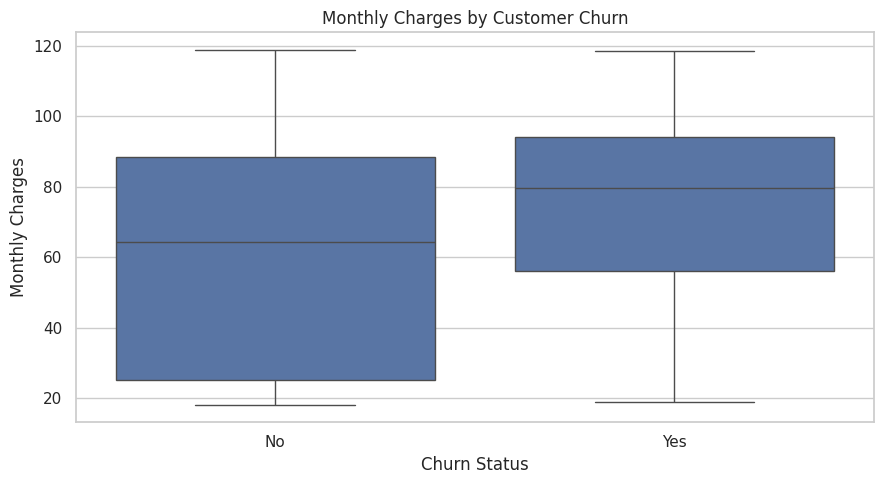

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x='Churn', y='MonthlyCharges')

plt.title('Monthly Charges by Customer Churn')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges')

plt.tight_layout()
plt.show()

### 8.4 Customer Tenure vs Churn

Customer tenure is compared across churn categories to investigate whether the length of a customer's relationship with the company is associated with churn.

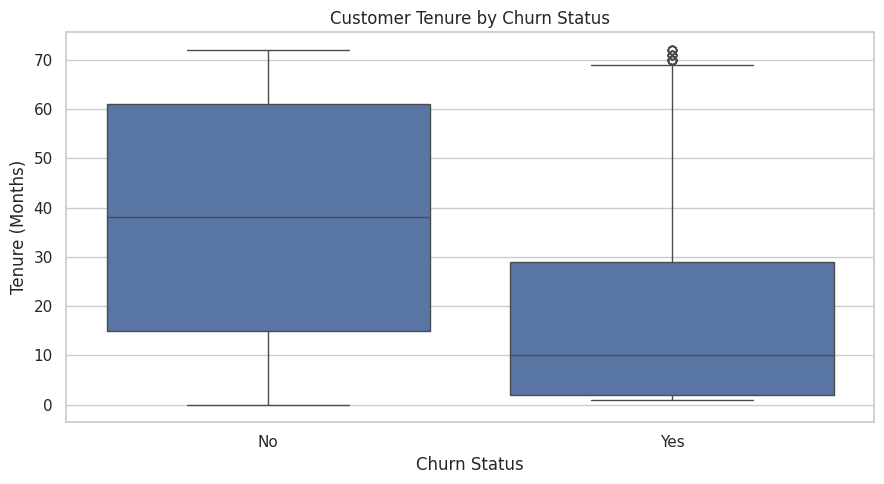

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x='Churn', y='tenure')

plt.title('Customer Tenure by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Tenure (Months)')

plt.tight_layout()
plt.show()

### 8.5 EDA Summary

The exploratory analysis provides an initial understanding of customer behaviour and churn patterns.

- Customer tenure distribution highlights differences in how long customers have stayed with the company.
- Contract type analysis helps examine the relationship between subscription duration and churn.
- Monthly charges comparison explores differences in billing amounts between churned and retained customers.
- Tenure comparison helps investigate whether newer customers are more likely to leave.

These observations provide useful insights for selecting features and developing classification models.

## 9. Feature Analysis and Selection

Exploratory analysis is used to investigate the relationship between individual features and customer churn.

- Categorical features are compared using churn percentages.
- Numerical features are examined through statistical summaries and visualizations.
- Potentially useful features are identified based on observed patterns.
- Final feature usefulness is evaluated through machine learning models.

### 9.1 Visualization of Categorical Feature Churn Rates

Horizontal bar charts are used to visualize customer churn percentages across different categories.

- Each bar represents the percentage of customers who churned within a category.
- The visualizations help identify categories associated with higher customer churn.
- These comparisons support the feature analysis process.

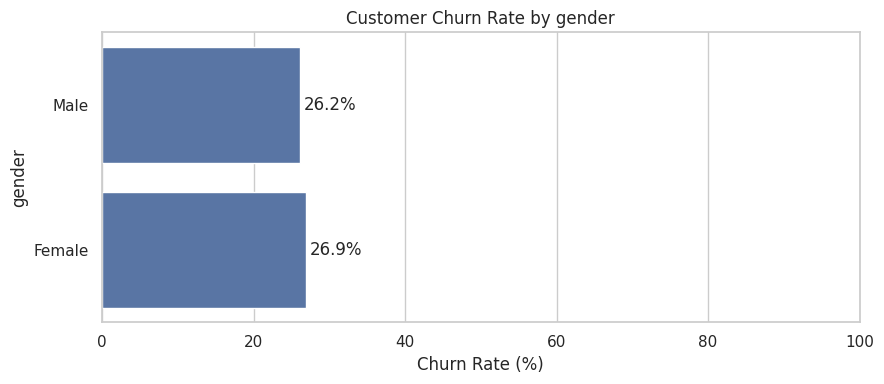

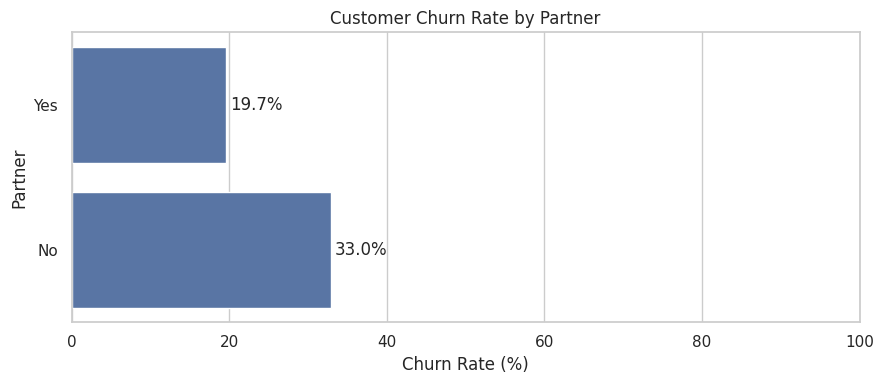

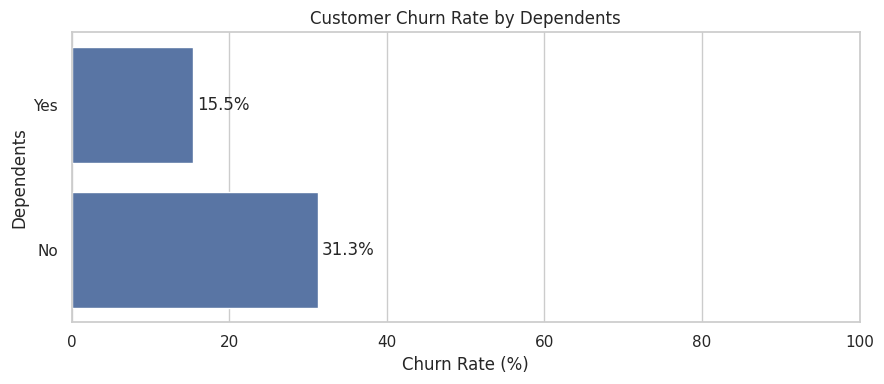

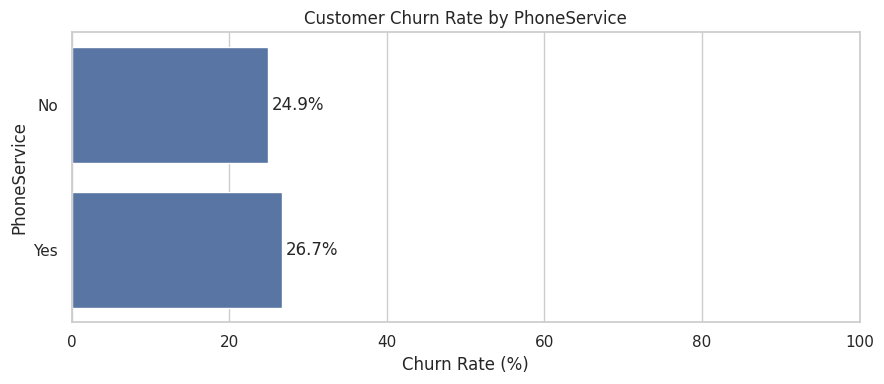

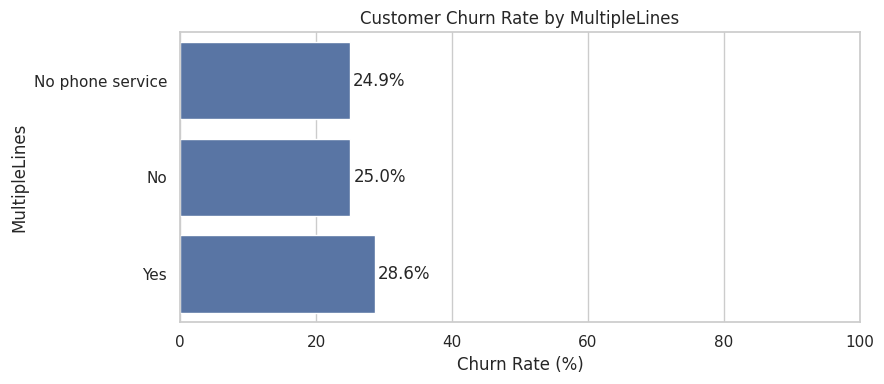

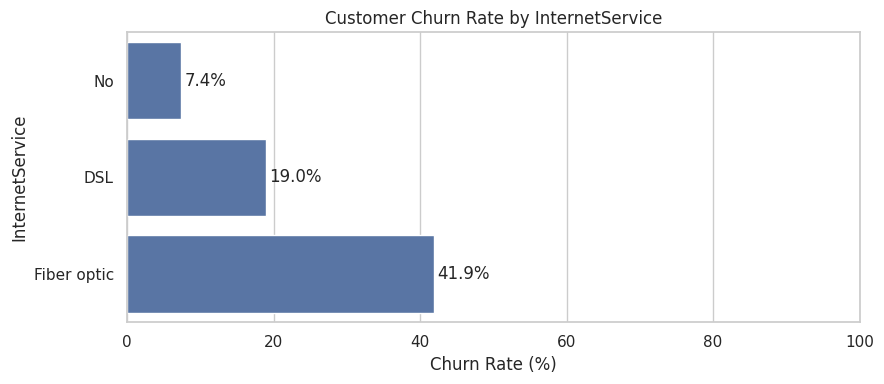

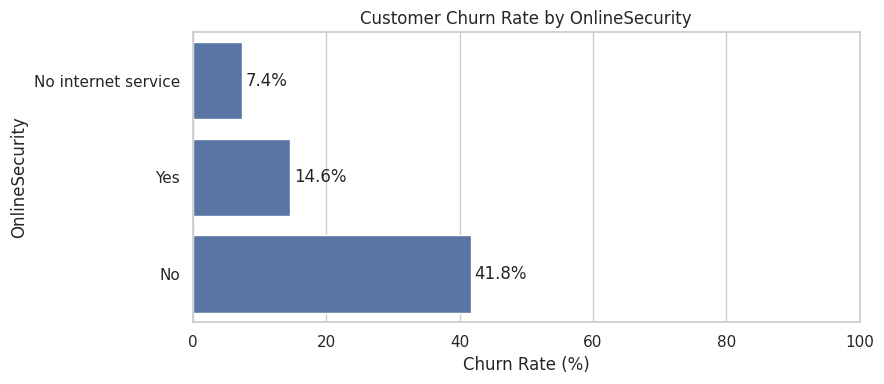

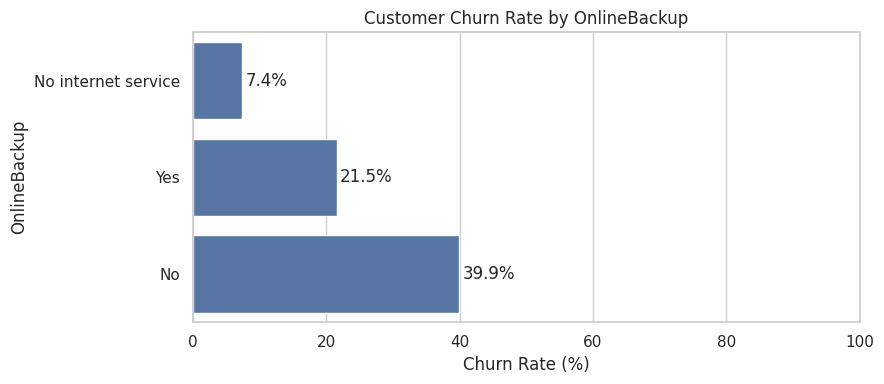

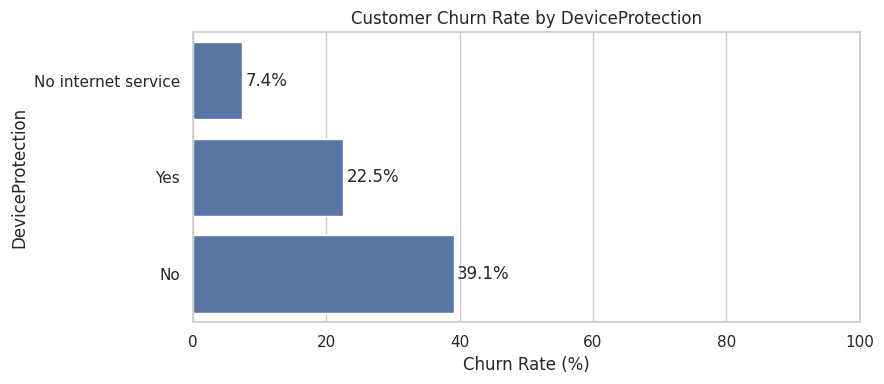

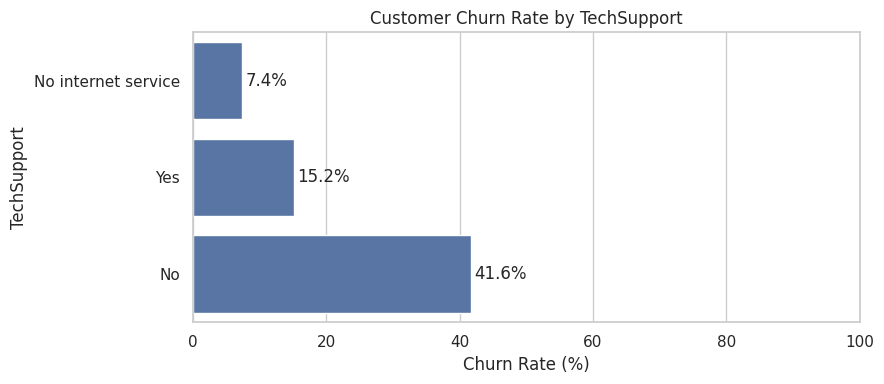

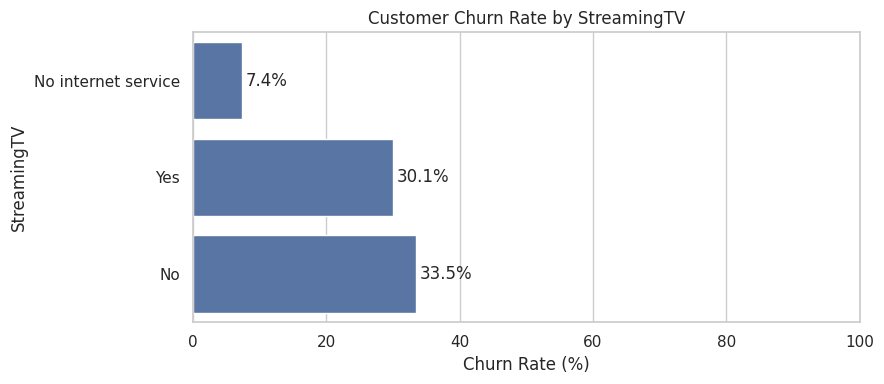

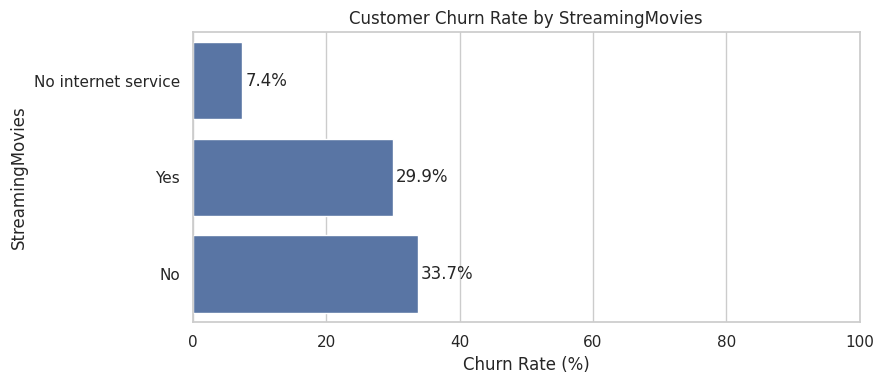

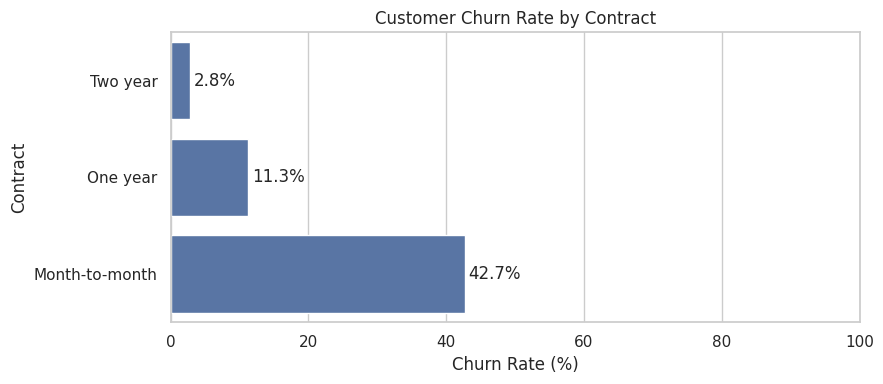

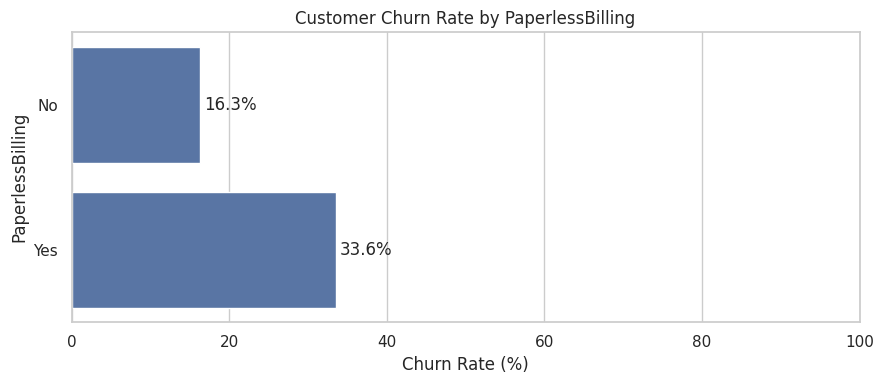

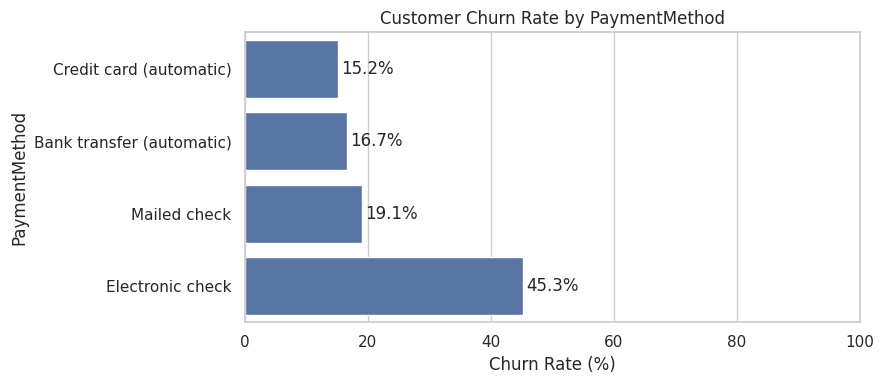

In [ ]:
categorical_features = df.select_dtypes(include='object').columns.tolist()

categorical_features.remove('customerID')
categorical_features.remove('Churn')

for feature in categorical_features:

    churn_rates = (
        df.groupby(feature, observed=False)['Churn']
        .apply(lambda x: (x == 'Yes').mean() * 100)
        .sort_values()
    )

    plt.figure(figsize=(9, max(4, len(churn_rates) * 0.6)))

    sns.barplot(
        x=churn_rates.values,
        y=churn_rates.index
    )

    plt.title(f'Customer Churn Rate by {feature}')
    plt.xlabel('Churn Rate (%)')
    plt.ylabel(feature)
    plt.xlim(0, 100)

    for index, value in enumerate(churn_rates.values):
        plt.text(value + 0.5, index, f'{value:.1f}%', va='center')

    plt.tight_layout()
    plt.show()

### 9.2 Categorical Feature Analysis Findings

The categorical feature analysis reveals several patterns associated with customer churn.

- Month-to-month contracts have a significantly higher churn rate (42.71%) than one-year (11.27%) and two-year contracts (2.83%).
- Customers using fiber optic internet show a higher churn rate (41.89%) compared to DSL customers (18.96%).
- Customers without online security and technical support have higher churn rates.
- Electronic check users have the highest churn rate (45.29%) among payment methods.
- Gender and phone service show relatively small differences in churn percentages.

These findings suggest that contract type, internet service, additional support services, and payment method may be important predictors of customer churn.

The final usefulness of each feature will be evaluated through machine learning models.

### 9.3 Numerical Feature Analysis

Numerical features are analyzed to understand differences between customers who churn and those who remain with the company.

- Mean and median values are compared across churn categories.
- Standard deviation is used to understand variation in customer data.
- These comparisons help identify potentially useful numerical predictors.

In [ ]:
numerical_features = ['tenure', 'MonthlyCharges', 'TotalCharges']

for feature in numerical_features:
    print(f"\nChurn Statistics for {feature}:")

    display(
        df.groupby('Churn')[feature]
        .agg(['mean', 'median', 'std'])
        .round(2)
    )


Churn Statistics for tenure:


,mean,median,std
Churn,,,
No,37.57,38.0,24.11
Yes,17.98,10.0,19.53



Churn Statistics for MonthlyCharges:


,mean,median,std
Churn,,,
No,61.27,64.43,31.09
Yes,74.44,79.65,24.67



Churn Statistics for TotalCharges:


,mean,median,std
Churn,,,
No,2555.34,1683.60,2329.46
Yes,1531.80,703.55,1890.82


### 9.4 Numerical Feature Visualization

Boxplots are used to compare numerical feature distributions between churned and retained customers.

They help identify differences in medians, spread, and potential outliers.

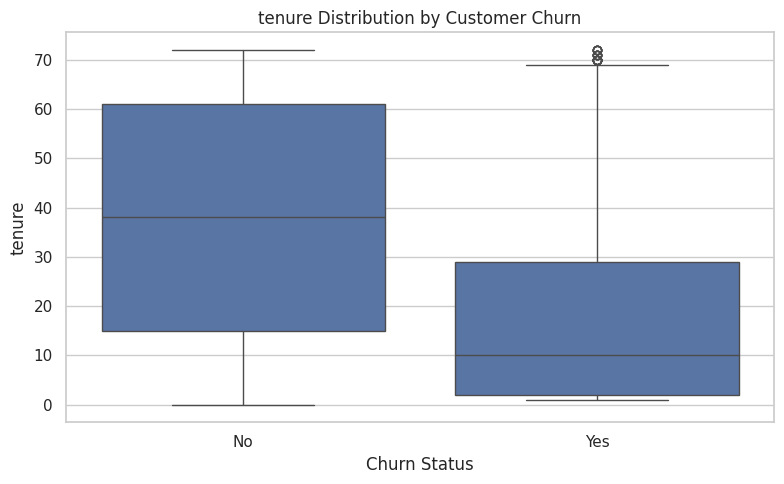

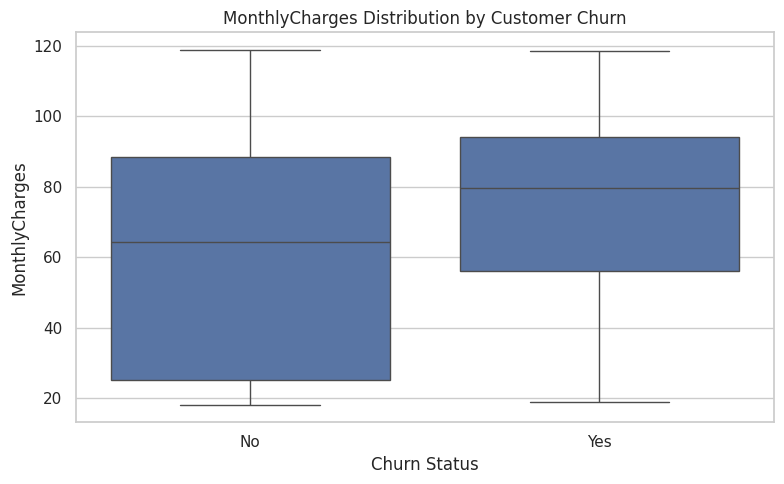

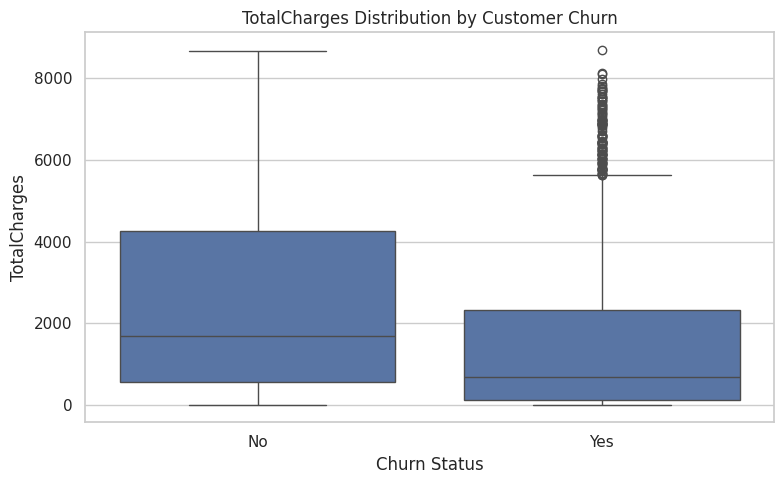

In [ ]:
for feature in numerical_features:
    plt.figure(figsize=(8, 5))

    sns.boxplot(data=df, x='Churn', y=feature)

    plt.title(f'{feature} Distribution by Customer Churn')
    plt.xlabel('Churn Status')
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

### 9.5 Numerical Feature Analysis Findings

The numerical analysis reveals several differences between churned and retained customers.

- Churned customers have substantially lower average tenure (17.98 months) than retained customers (37.57 months).
- Churned customers have higher average monthly charges (74.44) compared to retained customers (61.27).
- Churned customers have lower average total charges (1531.80) than retained customers (2555.34), potentially due to shorter customer relationships.

These observations suggest that tenure, monthly charges, and total charges may provide useful information for predicting customer churn.

### 9.6 Numerical Feature Correlation

A correlation heatmap is used to examine relationships between numerical features.

- Correlation values indicate the strength and direction of relationships between numerical variables.
- Highly correlated features may contain overlapping information.
- This analysis helps identify potential redundancy among numerical features.

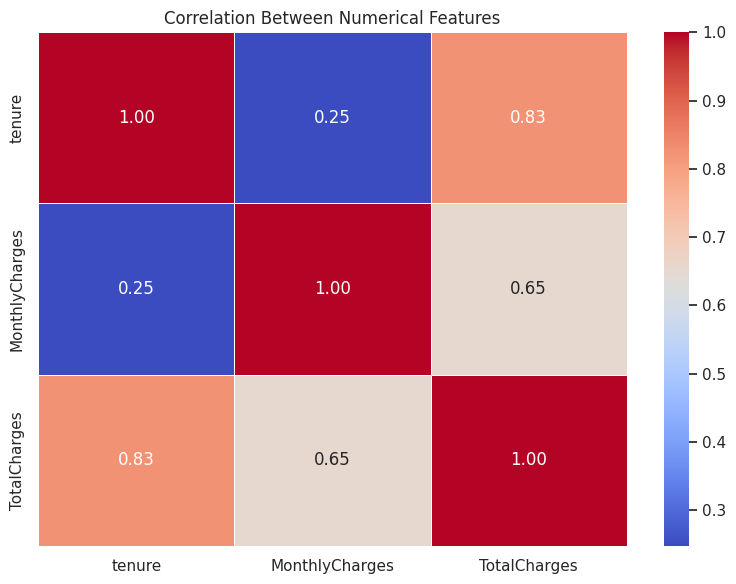

In [ ]:
plt.figure(figsize=(8, 6))

correlation_matrix = df[
    ['tenure', 'MonthlyCharges', 'TotalCharges']
].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between Numerical Features')
plt.tight_layout()
plt.show()

### 9.7 Feature Selection Decision

Based on the exploratory analysis:

- Contract type, tenure, internet service, payment method, and additional support services show notable relationships with customer churn.
- Gender and phone service show relatively small differences in individual churn rates.
- Numerical features such as tenure and monthly charges also show meaningful differences between churn categories.

All 19 available features are initially retained for model training because features with weak individual relationships may still contribute useful predictive information when combined with other variables.

Final feature importance will be examined after model training.

## 10. Data Preparation for Machine Learning

The dataset is prepared for machine learning by separating input features from the target variable.

- `customerID` is removed because it is a unique identifier.
- `Churn` is selected as the target variable.
- The remaining 19 columns are retained as input features.

In [ ]:
# Separate input features and target variable

X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Feature Shape: (7043, 19)
Target Shape: (7043,)

Target Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


## 11. Train-Test Split

The dataset is divided into training and testing subsets.

- 80% of the data is used for model training.
- 20% is reserved for final model evaluation.
- Stratification preserves the original churn class proportions.
- A fixed random state ensures reproducibility.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5634, 19)
Testing Features: (1409, 19)
Training Target: (5634,)
Testing Target: (1409,)


## 12. Data Preprocessing

The dataset contains numerical and categorical features that require different preprocessing techniques.

- Numerical features are handled using median imputation and standardization.
- Categorical features are handled using most frequent value imputation and one-hot encoding.
- Preprocessing is integrated into a pipeline to prevent data leakage.

In [ ]:
# Identify numerical and categorical columns

numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

print("\nNumber of Numerical Features:", len(numeric_features))
print("Number of Categorical Features:", len(categorical_features))

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of Numerical Features: 4
Number of Categorical Features: 15


### 12.1 Numerical and Categorical Preprocessing

Separate preprocessing pipelines are created for numerical and categorical features.

- Median imputation handles missing numerical values.
- StandardScaler standardizes numerical features.
- Most frequent imputation handles missing categorical values.
- OneHotEncoder converts categorical values into numerical representations.

In [ ]:
# Numerical preprocessing pipeline

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing pipeline

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

### 12.2 Combined Preprocessing Pipeline

ColumnTransformer combines the numerical and categorical preprocessing pipelines.

This ensures that each feature receives the appropriate preprocessing operations.

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 13. Baseline Model

A baseline model is created to establish a reference performance before training more advanced machine learning algorithms.

The DummyClassifier predicts the most frequent class without learning patterns from customer features.

In [ ]:
# Create and train the baseline model

baseline_model = DummyClassifier(strategy='most_frequent')

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print("Baseline Model Accuracy:", round(baseline_accuracy * 100, 2), "%")

Baseline Model Accuracy: 73.46 %


### 13.2 Baseline Results Analysis

The baseline model achieved 73.46% accuracy by predicting every customer as non-churn.

- It correctly classified all 1,035 non-churning customers.
- It failed to identify all 374 customers who actually churned.
- Precision and recall for the churn class (Yes) are both 0.00.
- The confusion matrix confirms that the model cannot identify customers at risk of leaving.

This demonstrates why accuracy alone is insufficient for evaluating customer churn prediction. More advanced models are required to identify potential churners effectively.

## 15. Machine Learning Models
Two machine learning classification algorithms are selected for customer churn prediction.
- Logistic Regression: A linear classification algorithm suitable for binary classification.
- Random Forest: An ensemble learning algorithm that combines multiple decision trees to make predictions.

Both models use the same preprocessing pipeline to ensure consistent data preparation.

In [ ]:
logistic_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

random_forest_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE
    ))
])

print("Both machine learning models created successfully!")

Both machine learning models created successfully!


## 16. Model Comparison Using Cross-Validation
The baseline and two machine learning models are evaluated using five-fold stratified cross-validation.
- Accuracy is used as the initial comparison metric.
- Stratified folds maintain the class distribution across validation splits.
- The mean cross-validation accuracy is used to compare model performance against the baseline.

In [ ]:
models = {
    'Baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': logistic_pipeline,
    'Random Forest': random_forest_pipeline
}

model_results = []

for model_name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='accuracy'
    )

    model_results.append({
        'Model': model_name,
        'Mean CV Accuracy': scores.mean(),
        'Standard Deviation': scores.std()
    })

model_comparison = pd.DataFrame(model_results)

model_comparison['Mean CV Accuracy'] = (
    model_comparison['Mean CV Accuracy'] * 100
).round(2)

model_comparison['Standard Deviation'] = (
    model_comparison['Standard Deviation'] * 100
).round(2)

display(model_comparison.sort_values(
    by='Mean CV Accuracy',
    ascending=False
).reset_index(drop=True))

,Model,Mean CV Accuracy,Standard Deviation
0,Logistic Regression,80.21,1.16
1,Random Forest,78.56,1.24
2,Baseline,73.46,0.01


### 16.1 Model Comparison Findings

The cross-validation results show that both machine learning models outperform the baseline.
- Logistic Regression achieved the highest mean accuracy of 80.21%.
- Random Forest achieved 78.56% mean accuracy.
- The baseline model achieved 73.46% mean accuracy.
- Logistic Regression performed best, with an improvement of 6.75 percentage points over the baseline.

Logistic Regression is selected as the leading model for further evaluation on the unseen test dataset.

## 17. Model Training
Both machine learning models are trained using the training dataset.
- Logistic Regression is trained as the leading model based on cross-validation accuracy.
- Random Forest is also trained for comparison.
- The test dataset remains unseen during training.

In [ ]:
logistic_pipeline.fit(X_train, y_train)
random_forest_pipeline.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


## 18. Model Evaluation on Test Data
The trained models are evaluated using the unseen test dataset to measure their ability to predict customer churn.
- Accuracy measures the overall proportion of correct predictions.
- Precision measures how many predicted churn cases were actually churn cases.
- Recall measures how many actual churn cases were correctly identified.
- Confusion matrices provide a detailed view of correct and incorrect predictions.

In [ ]:
logistic_predictions = logistic_pipeline.predict(X_test)
random_forest_predictions = random_forest_pipeline.predict(X_test)

evaluation_results = []

for model_name, predictions in [
    ('Logistic Regression', logistic_predictions),
    ('Random Forest', random_forest_predictions)
]:
    evaluation_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, pos_label='Yes'),
        'Recall': recall_score(y_test, predictions, pos_label='Yes')
    })

evaluation_df = pd.DataFrame(evaluation_results)

for column in ['Accuracy', 'Precision', 'Recall']:
    evaluation_df[column] = (evaluation_df[column] * 100).round(2)

display(evaluation_df)

,Model,Accuracy,Precision,Recall
0,Logistic Regression,80.55,65.72,55.88
1,Random Forest,77.57,60.00,46.52


### 18.1 Test Performance Analysis

The test evaluation shows that Logistic Regression performs better than Random Forest.
- Logistic Regression achieved 80.55% accuracy, compared to 77.57% for Random Forest.
- Logistic Regression achieved 65.72% precision, indicating better reliability when identifying potential churners.
- Logistic Regression achieved 55.88% recall, identifying more actual churners than Random Forest (46.52%).
- Both models perform better than the baseline accuracy of 73.46%.

Logistic Regression is selected as the better-performing model based on the current evaluation results.

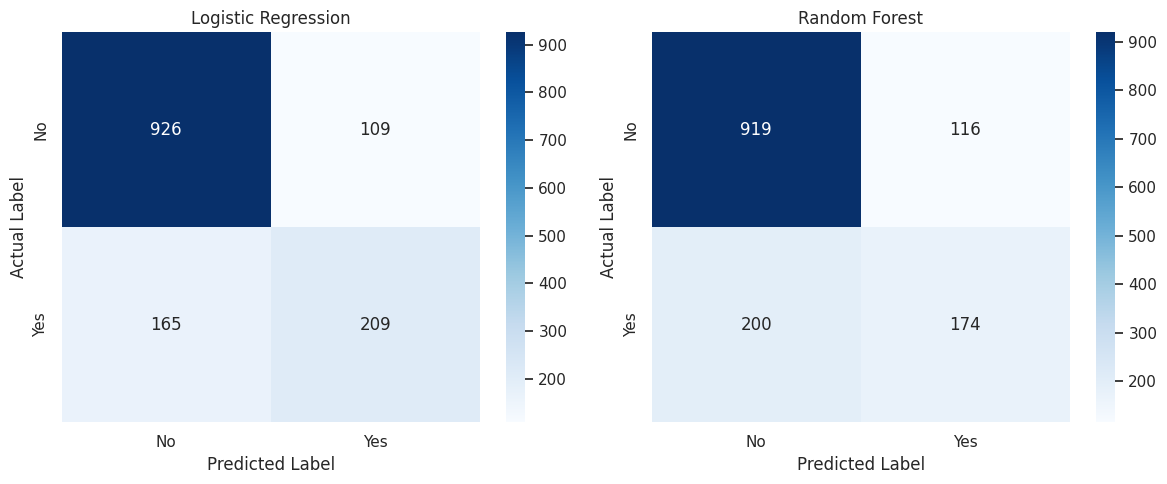

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, model_name, predictions in [
    (axes[0], 'Logistic Regression', logistic_predictions),
    (axes[1], 'Random Forest', random_forest_predictions)
]:
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=['No', 'Yes']
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No', 'Yes'],
        yticklabels=['No', 'Yes'],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

### 18.3 Classification Reports
Classification reports provide detailed precision, recall, and F1-score values for both churn classes.
- The No class represents customers who remain with the company.
- The Yes class represents customers who leave the company.
- F1-score provides a balance between precision and recall.

In [ ]:
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    logistic_predictions,
    zero_division=0
))

print("\nRANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    random_forest_predictions,
    zero_division=0
))

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

          No       0.82      0.89      0.85      1035
         Yes       0.60      0.47      0.52       374

    accuracy                           0.78      1409
   macro avg       0.71      0.68      0.69      1409
weighted avg       0.76      0.78      0.77      1409



### 18.4 Classification Report Findings

The classification reports provide further insight into the performance of both models.
- Logistic Regression achieved an F1-score of 0.60 for the churn class, compared to 0.52 for Random Forest.
- Logistic Regression correctly identified 55.88% of actual churn cases, while Random Forest identified 46.52%.
- Both models perform better at identifying customers who stay than customers who leave.
- Logistic Regression provides a better balance between precision and recall for the churn class.

Based on these results, Logistic Regression is selected as the final model for customer churn prediction.

## 19. Error Analysis
Error analysis examines cases where the selected model produces incorrect predictions.
- False Positives: Customers predicted to churn who actually stay.
- False Negatives: Customers predicted to stay who actually churn.
- Examining these errors helps identify limitations and opportunities for improving the model.

In [ ]:
error_analysis = X_test.copy()

error_analysis['Actual Churn'] = y_test
error_analysis['Predicted Churn'] = logistic_predictions

incorrect_predictions = error_analysis[
    error_analysis['Actual Churn'] !=
    error_analysis['Predicted Churn']
].copy()

false_positives = incorrect_predictions[
    (incorrect_predictions['Actual Churn'] == 'No') &
    (incorrect_predictions['Predicted Churn'] == 'Yes')
]

false_negatives = incorrect_predictions[
    (incorrect_predictions['Actual Churn'] == 'Yes') &
    (incorrect_predictions['Predicted Churn'] == 'No')
]

print("Total Incorrect Predictions:", len(incorrect_predictions))
print("False Positives:", len(false_positives))
print("False Negatives:", len(false_negatives))

display(incorrect_predictions.head(10))

Total Incorrect Predictions: 274
False Positives: 109
False Negatives: 165


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual Churn,Predicted Churn
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,No,Yes
5748,Female,0,No,No,21,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),99.85,1992.55,No,Yes
1639,Male,1,No,No,17,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,45.05,770.60,Yes,No
2136,Male,0,No,Yes,15,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Electronic check,91.00,1430.05,No,Yes
950,Male,1,No,No,2,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Mailed check,44.95,85.15,Yes,No
2488,Male,0,No,No,31,Yes,No,DSL,No,No,Yes,Yes,No,No,Month-to-month,Yes,Electronic check,55.25,1715.65,Yes,No
2519,Male,0,Yes,No,2,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,No,Month-to-month,Yes,Electronic check,91.45,171.45,No,Yes
3510,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,75.25,576.70,No,Yes
523,Female,0,No,No,23,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,No,Bank transfer (automatic),75.60,1758.60,Yes,No
5086,Male,0,No,No,45,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Electronic check,20.40,930.45,Yes,No


### 19.1 Error Analysis Findings

The selected Logistic Regression model produced 274 incorrect predictions.
- 109 false positives occurred when customers were predicted to churn but actually stayed.
- 165 false negatives occurred when customers were predicted to stay but actually churned.
- False negatives are particularly important because potential churners may remain unidentified, resulting in missed customer retention opportunities.
- Some incorrect predictions involve customers with month-to-month contracts, short tenure, fiber optic internet, or electronic check payments. These patterns overlap with characteristics associated with churn, making individual predictions more challenging.

The errors indicate that customer churn depends on multiple interacting factors and cannot always be predicted correctly using the current model.

## 20. Conclusion

The Customer Churn Prediction project applied supervised machine learning techniques to identify customers who may leave a telecommunications company.

- The IBM Telco Customer Churn dataset contained 7,043 customer records and 19 predictor features.
- Exploratory Data Analysis identified relationships between churn and factors such as contract type, tenure, internet service, and payment method.
- Logistic Regression achieved the best cross-validation accuracy of 80.21%.
- On the unseen test dataset, Logistic Regression achieved 80.55% accuracy, 65.72% precision, and 55.88% recall for the churn class.
- Logistic Regression outperformed Random Forest across the evaluated test metrics.

The results demonstrate that machine learning can support customer retention by identifying potential churners. However, further improvements are needed to reduce false negatives and improve churn detection.